> Note: Gaada dataset aslinya, tapi ini works buat semua jenis dataset asal ngaturnya bener

In [1]:
import tensorflow as tf
import keras
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

## **Load Dataset**

In [2]:
DATASET_PATH = './Dataset/'
classes = os.listdir(DATASET_PATH)

X, Y = [], []

for idx, clx in enumerate(classes):
    folder_path = os.path.join(DATASET_PATH, clx)

    for raw_path in os.listdir(folder_path):
        img_path = os.path.join(folder_path, raw_path)

        img = tf.keras.utils.load_img(img_path, target_size=(224, 224), color_mode='grayscale')
        img = tf.keras.utils.img_to_array(img)

        X.append(img)
        Y.append(idx)

X = np.array(X)
Y = np.array(Y)

print("Dataset loaded successfully!")
print(f"Shape X: {X.shape}, Shape Y: {Y.shape}")

Dataset loaded successfully!
Shape X: (2520, 224, 224, 1), Shape Y: (2520,)


## **Preprocessing**

In [3]:
X = X.astype('float32') / 255.0
X_train, X_n, Y_train, Y_n = train_test_split(X, Y, test_size=0.2, random_state=23)
X_val, X_test, Y_val, Y_test = train_test_split(X_n, Y_n, test_size=0.5, random_state=23)

y_train = keras.utils.to_categorical(Y_train, num_classes=len(classes))
y_val = keras.utils.to_categorical(Y_val, num_classes=len(classes))
y_test = keras.utils.to_categorical(Y_test, num_classes=len(classes))

## **Framework**

In [4]:
model = keras.Sequential([
    keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 1)),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation='relu'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(128, (3, 3), activation='relu'),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(len(classes), activation='softmax')
])

model.summary()

c:\Users\mxlov\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,168,771 (42.61 MB)

 Trainable params: 11,168,771 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

## **Training**

In [5]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 43s 658ms/step - accuracy: 0.5749 - loss: 0.9633 - val_accuracy: 0.8294 - val_loss: 0.6045
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 43s 677ms/step - accuracy: 0.9206 - loss: 0.3576 - val_accuracy: 0.9881 - val_loss: 0.1250
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 43s 683ms/step - accuracy: 0.9881 - loss: 0.0910 - val_accuracy: 0.9960 - val_loss: 0.0366
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 41s 642ms/step - accuracy: 0.9950 - loss: 0.0354 - val_accuracy: 1.0000 - val_loss: 0.0161
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 40s 632ms/step - accuracy: 0.9965 - loss: 0.0181 - val_accuracy: 1.0000 - val_loss: 0.0119
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 41s 653ms/step - accuracy: 0.9980 - loss: 0.0115 - val_accuracy: 1.0000 - val_loss: 0.0059
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 47s 751ms/step - accuracy: 0.9985 - loss: 0.0079 - val_accuracy: 1.0000 - val_loss: 0.0033
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 42s 661ms/step - accuracy: 1.0000 - loss: 0.0056 - val_accu

In [6]:
acc, loss = model.evaluate(X_train, y_train)
print(f"Training Accuracy: {acc * 100:.2f}%")
print(f"Training Loss: {loss:.2f}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 142ms/step - accuracy: 1.0000 - loss: 0.0017
Training Accuracy: 0.17%
Training Loss: 1.00


## Predict

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 138ms/step


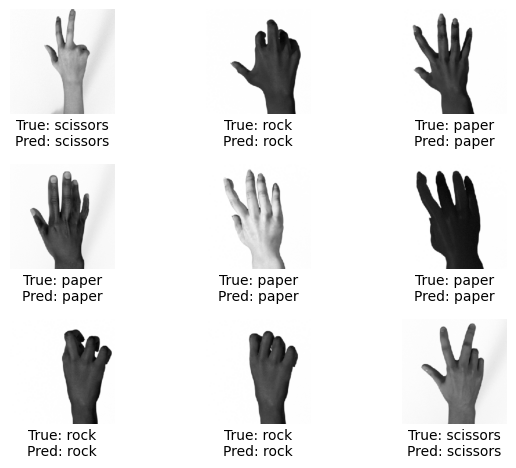

In [11]:
prediction = model.predict(X_test)
pred = np.argmax(prediction, axis=1)
true = np.argmax(y_test, axis=1)

for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(X_test[i], cmap="gray")
    plt.axis('off')
    plt.text(0.5, -0.15, f"True: {classes[true[i]]}", ha='center', transform=plt.gca().transAxes)
    plt.text(0.5, -0.3, f"Pred: {classes[pred[i]]}", ha='center', transform=plt.gca().transAxes)

plt.tight_layout()
plt.show()

## Plot

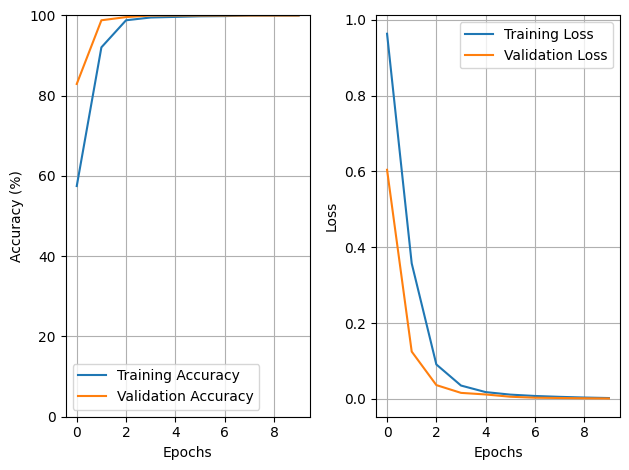

In [20]:
plt.subplot(1, 2, 1)
plt.plot([x * 100 for x in history.history['accuracy']], label="Training Accuracy")
plt.plot([x * 100 for x in history.history['val_accuracy']], label="Validation Accuracy")
plt.grid(True)
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label="Training Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.grid(True)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()